In [83]:
import torch
import matplotlib.pyplot as plt

In [85]:
words = open('names.txt', 'r').read().splitlines()
words[:3]

['emma', 'olivia', 'ava']

In [86]:
# since we're building a character level language model we'll have vocabular of only 27 characters
# build vocabulary and mapping from characters to integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i + 1 for i , s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}

In [87]:
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")   
device = torch.device("cpu")
device

device(type='cpu')

In [88]:
# build dataset
# trigram dataset
block_size = 8
def build_dataset(words):
    X, y = [], []
    for word in words:
        context = [0] * block_size
        for ch in word + '.':
            ix = stoi[ch]
            X.append(context)
            y.append(ix)
            context = context[1:] + [ix]
    X = torch.tensor(X).to(device)
    y = torch.tensor(y).to(device)
    return X, y

In [89]:
# create test train dev splits
import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))
X_tr, y_tr = build_dataset(words=words[:n1])
X_dev, y_dev = build_dataset(words=words[n1:n2])
X_te, y_te = build_dataset(words=words[n2:])

In [96]:
class Linear:
    def __init__(self, fan_in, fan_out, bias=True):
        self.bias = bias
        # pytorch initializes weight as (fan_out, fan_in) and transposes on multiplication
        self.w = (
            torch.randn((fan_in, fan_out)) * 5 / 3 * ((1 / fan_in) ** 0.5)
        )  # kaiming He initializatoin 5/3 for tanh
        self.b = torch.zeros(fan_out) if bias else None

    def __call__(self, x):
        self.out = x @ self.w
        if self.b is not None:
            self.out += self.b
        return self.out

    def parameters(self):
        return [self.w] + ([] if self.b is None else [self.b])


class BatchNorm1D:
    def __init__(self, dim, eps=1e-5, momentum=0.1):
        self.eps = eps
        self.momentum = momentum
        self.training = True
        self.gamma = torch.ones(dim)  # batch_weight
        self.beta = torch.zeros(dim)  # batch_bias

        # running buffer parametres
        self.running_mean = torch.zeros(dim)
        self.running_var = torch.ones(dim)

    def __call__(self, x):  # x.shape -> (n_batch, n_features)
        if self.training:
            if x.ndim == 2:
                dim = 0
            elif x.ndim == 3:
                dim = (0, 1)
            x_mean = x.mean(dim)  # mean along batch dimension
            x_var = x.var(dim, unbiased=False)  # variance along batch dimension
        else:
            x_mean = self.running_mean
            x_var = self.running_var
        x_hat = (x - x_mean) / torch.sqrt(x_var + self.eps)
        self.out = x_hat * self.gamma + self.beta

        # update the buffers when training
        if self.training:
            self.running_mean = (
                1 - self.momentum
            ) * self.running_mean + self.momentum * x_mean
            self.running_var = (
                1 - self.momentum
            ) * self.running_var + self.momentum * x_var
        return self.out

    def parameters(self):
        return [self.gamma, self.beta]


class Tanh:
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out

    def parameters(self):
        return []


class Embedding:
    def __init__(self, n_classes, n_embed):
        self.w = torch.randn((n_classes, n_embed))

    def __call__(self, x):
        self.out = self.w[x]
        return self.out

    def parameters(self):
        return [self.w]


class Flatten:
    def __init__(self, n):
        self.n = n

    def __call__(self, x):
        B, T, C = x.shape
        x = x.view(B, T // self.n, C * self.n)
        if x.shape[1] == 1:
            x= x.squeeze(1)
        self.out = x
        return self.out

    def parameters(self):
        return []


class Sequential:
    def __init__(self, layers):
        self.layers = layers

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        self.out = x
        return self.out

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

In [97]:
# nn parameters
n_embed = 10 # dimensions of embedding space
n_hidden = 68 # no of neurons in hidden laer
vocab_size = len(stoi)

g = torch.Generator().manual_seed(123)

model = Sequential([
    Embedding(vocab_size, n_embed),
    Flatten(n=2), Linear(n_embed * 2, n_hidden, bias=False),BatchNorm1D(n_hidden),  Tanh(), 
    Flatten(n=2), Linear(n_hidden * 2, n_hidden, bias=False),BatchNorm1D(n_hidden),  Tanh(), 
    Flatten(n=2), Linear(n_hidden * 2, n_hidden, bias=False),BatchNorm1D(n_hidden),  Tanh(), 
    Linear(          n_hidden, vocab_size),
])

with torch.no_grad():
    # make last layer less confident at start
    # this will make the initial loss close to -ln(1/27)
    model.layers[-1].w *= 0.1
    

parameters = model.parameters()
# print nuber of parameters
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad = True

22397


In [98]:

max_steps = 200000
batch_size = 32
losses = []
for i in range(max_steps):
    # minibatch
    ix = torch.randint(0, X_tr.shape[0], (batch_size,)).to(device)
    Xb, yb = X_tr[ix], y_tr[ix]

    # forward pass
    logits = model(Xb)
    loss = torch.nn.functional.cross_entropy(logits, yb)

    # backward pass
    # for layer in model.layers:
    #     layer.out.retain_grad() # retain gradients for non-leaf tensors remove after debugging during training

    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    losses.append(loss.item())
    if i % 20000 == 0:
        print(f'{i:7d}/{max_steps} : {loss.item():.4f}')

      0/200000 : 3.2975
  20000/200000 : 2.3775
  40000/200000 : 1.8963
  60000/200000 : 2.0631
  80000/200000 : 1.6329
 100000/200000 : 1.8816
 120000/200000 : 1.9674
 140000/200000 : 1.7677
 160000/200000 : 2.2902
 180000/200000 : 1.9402


In [99]:
for layer in model.layers:
    layer.training = False

In [100]:
import torch.nn.functional as F
# test loss and val loss
@torch.no_grad()
def split_loss(split):
    x, y = {"train": (X_tr, y_tr), "val": (X_dev, y_dev), "test": (X_te, y_te)}[split]
    logits = model(x)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())
split_loss('train')
split_loss('val')

train 1.9352623224258423
val 2.0267066955566406


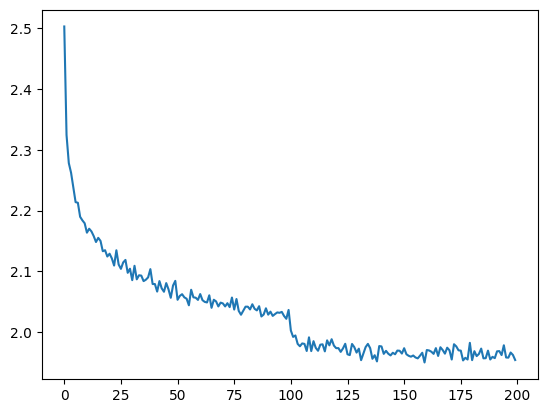

In [101]:
plt.plot(torch.tensor(losses).view(-1, 1000).mean(1));

In [102]:
g = torch.Generator().manual_seed(47)
# sample from the model
for _ in range(20):
    out = []
    context = [0] * block_size

    while True:
        x = torch.tensor(context).view(1, -1)
        for layer in model.layers:
            x = layer(x)
        p = torch.softmax(x, dim=1)

        ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix==0:
            break
    print("".join([itos[i] for i in out]))
        

kyler.
frajmae.
boorrus.
cardar.
heatikah.
salvarri.
ranimi.
bamanue.
laveln.
naiypa.
harthik.
jamissa.
xiella.
army.
jawsye.
jaylynn.
adariah.
yean.
roseigh.
azagar.


In [103]:
# visualize how the shape evolves throughout the network

ix = torch.randint(0, X_tr.shape[0], (batch_size,))
Xb, yb = X_tr[ix], y_tr[ix]

x = Xb
for layer in model.layers:
    print(f'{"Input shape":14s} {str(tuple(x.shape)):12s}', end="-->   ")
    x = layer(x)
    print(f'Layer: {layer.__class__.__name__:12s}', end="-->   ")
    print(f'{"Output shape":14s} {str(tuple(x.shape)):19s}')

Input shape    (32, 8)     -->   Layer: Embedding   -->   Output shape   (32, 8, 10)        
Input shape    (32, 8, 10) -->   Layer: Flatten     -->   Output shape   (32, 4, 20)        
Input shape    (32, 4, 20) -->   Layer: Linear      -->   Output shape   (32, 4, 68)        
Input shape    (32, 4, 68) -->   Layer: BatchNorm1D -->   Output shape   (32, 4, 68)        
Input shape    (32, 4, 68) -->   Layer: Tanh        -->   Output shape   (32, 4, 68)        
Input shape    (32, 4, 68) -->   Layer: Flatten     -->   Output shape   (32, 2, 136)       
Input shape    (32, 2, 136)-->   Layer: Linear      -->   Output shape   (32, 2, 68)        
Input shape    (32, 2, 68) -->   Layer: BatchNorm1D -->   Output shape   (32, 2, 68)        
Input shape    (32, 2, 68) -->   Layer: Tanh        -->   Output shape   (32, 2, 68)        
Input shape    (32, 2, 68) -->   Layer: Flatten     -->   Output shape   (32, 136)          
Input shape    (32, 136)   -->   Layer: Linear      -->   Output shape